In [26]:
import sys
import os
from typing import NamedTuple

import numpy as np
import pandas as pd

from sklearn.cross_decomposition import CCA
from sklearn.model_selection import train_test_split, TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils
# noinspection PyUnresolvedReferences
from utils import artificializer

# noinspection PyUnresolvedReferences
from models import hgm
# noinspection PyUnresolvedReferences
from models import bom

In [27]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/worm-2025-fieseler/import/models/hgm.py'>

# data

In [28]:
selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
			   'RMDDR', 'SMDDR', 'SMDDL',				# C
			   'AVAR', 'AVAL',							# M
			   'ALA', 'AWBR']							# O
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']


# read_ids_gcamp = list(range(0, 33+1))
read_ids_gcamp = [0,   # minrevs
				  1,   # minswitch
				  7,   # maxswitch
				  11,  # median
				  12,  # maxrevs
				  17,  # mean
				  19,  # paper
				  21]  # clean
# read_ids_gcamp = [19]
plot_id_gcamp = 19


dims = 1

artificial = True
if artificial:
	dims_generation = 2
	weights = (0.1, -0.25)

In [29]:
# read

path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_data(path, read_ids_gcamp)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# remove unused discrete state labels
discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])


# generate
if artificial:
	file_ids_art = list()
	filenames_art = list()

	discrete_states_art = list()
	eigenworms_art = list()

	modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()

	for i in range(len(file_ids_gcamp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames_gcamp[i],
														 traces_gcamp[i].columns,
														 eigenworms_gcamp[i],
														 discrete_states_gcamp[i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)

		modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

		file_ids_art.append(file_ids_gcamp[i])

		discrete_states_art.append(discrete_states_gcamp[i].copy())
		eigenworms_art.append(eigenworms_gcamp[i].copy())



if artificial:
	plot_id_art = plot_id_gcamp
	filename = filenames_art[file_ids_art.index(plot_id_art)]
	file_id = file_ids_art[file_ids_art.index(plot_id_art)]

	traces = traces_art[file_ids_art.index(plot_id_art)]

	modes = modes_art[file_ids_art.index(plot_id_art)]
	traces_reconstructed = traces_reconstructed_art[file_ids_art.index(plot_id_art)]
	traces_residual = traces_residual_art[file_ids_art.index(plot_id_art)]

	eigenworms = eigenworms_art[file_ids_art.index(plot_id_art)]
	discrete_states = discrete_states_art[file_ids_art.index(plot_id_art)]

else:
	filename = filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]
	traces = traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)]
	eigenworms = eigenworms_gcamp[file_ids_gcamp.index(plot_id_gcamp)]
	discrete_states = discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)]

In [30]:
selection_n = [label for label in selection_n if label in traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)].columns]

In [31]:
# if artificial:
# 	plot_utils.plot_traces(f'[{filename}] modes',
# 						   discrete_states[['REV']],
# 						   modes,
# 						   plots_per_row=1, ylimits=None)

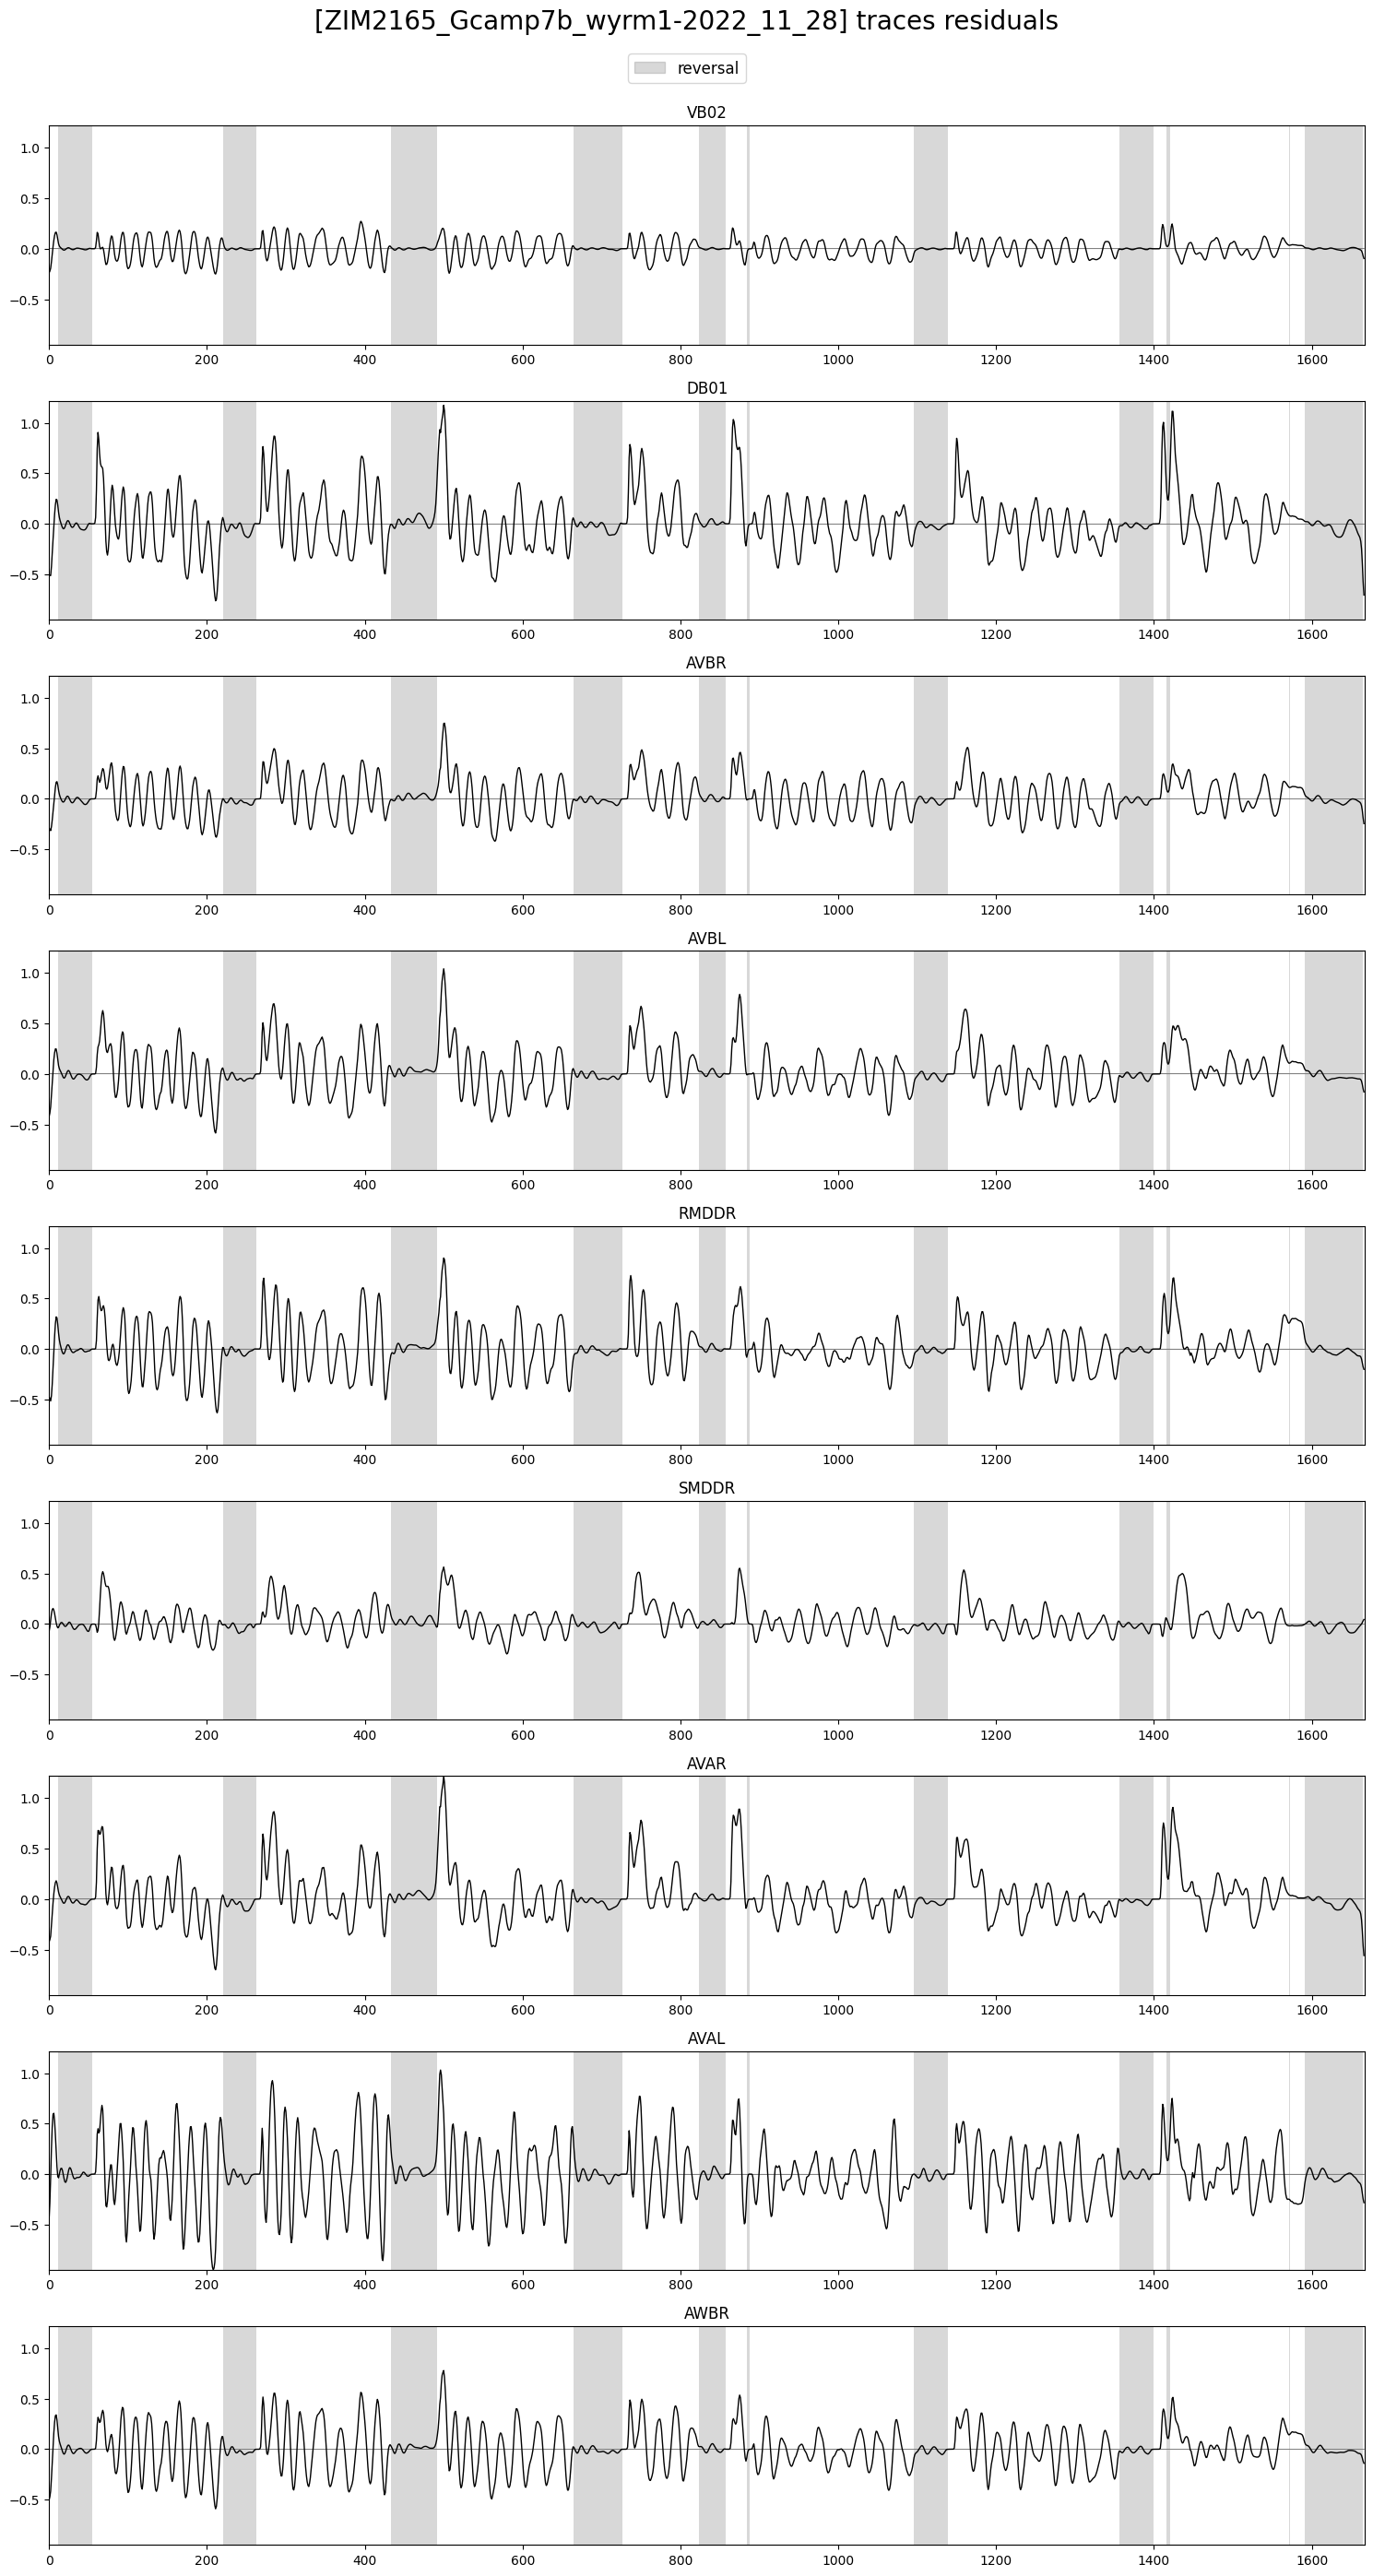

In [32]:
if artificial:
	plot_utils.plot_traces(f'[{filename}] traces residuals',
						   discrete_states[['REV']],
						   traces_residual[selection_n],
						   plots_per_row=1, ylimits=None)

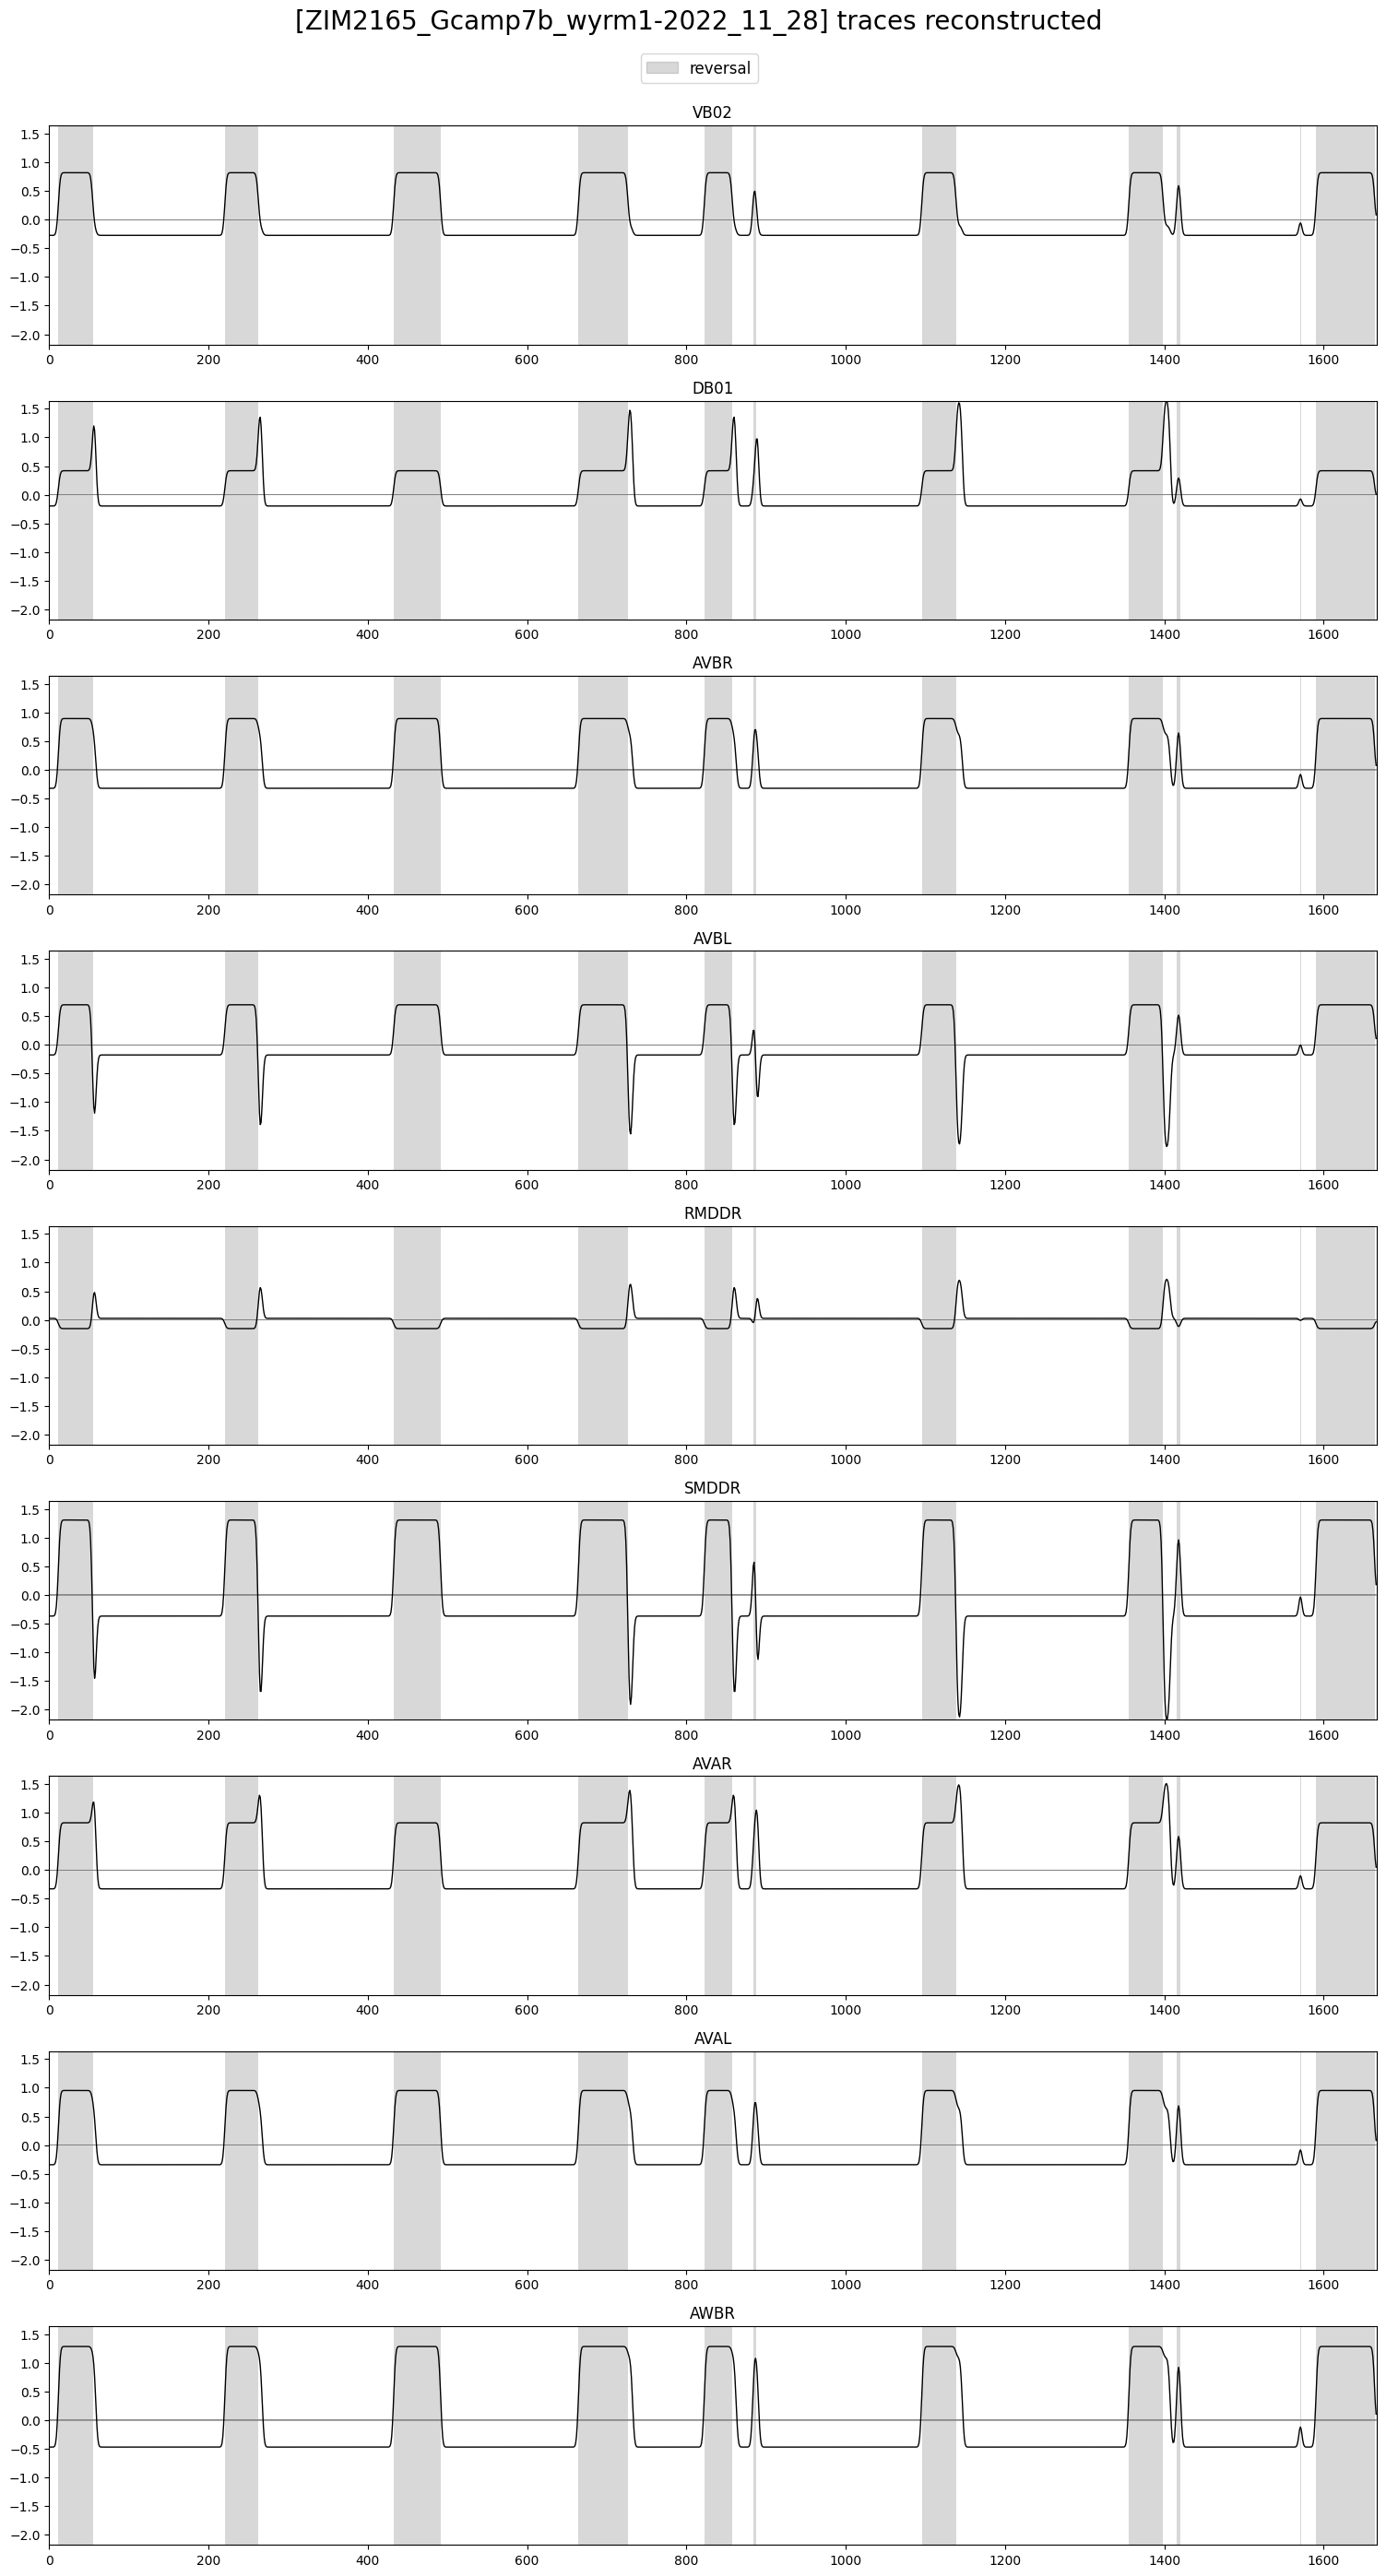

In [33]:
if artificial:
	plot_utils.plot_traces(f'[{filename}] traces reconstructed',
						   discrete_states[['REV']],
						   traces_reconstructed[selection_n],
						   plots_per_row=1, ylimits=None)

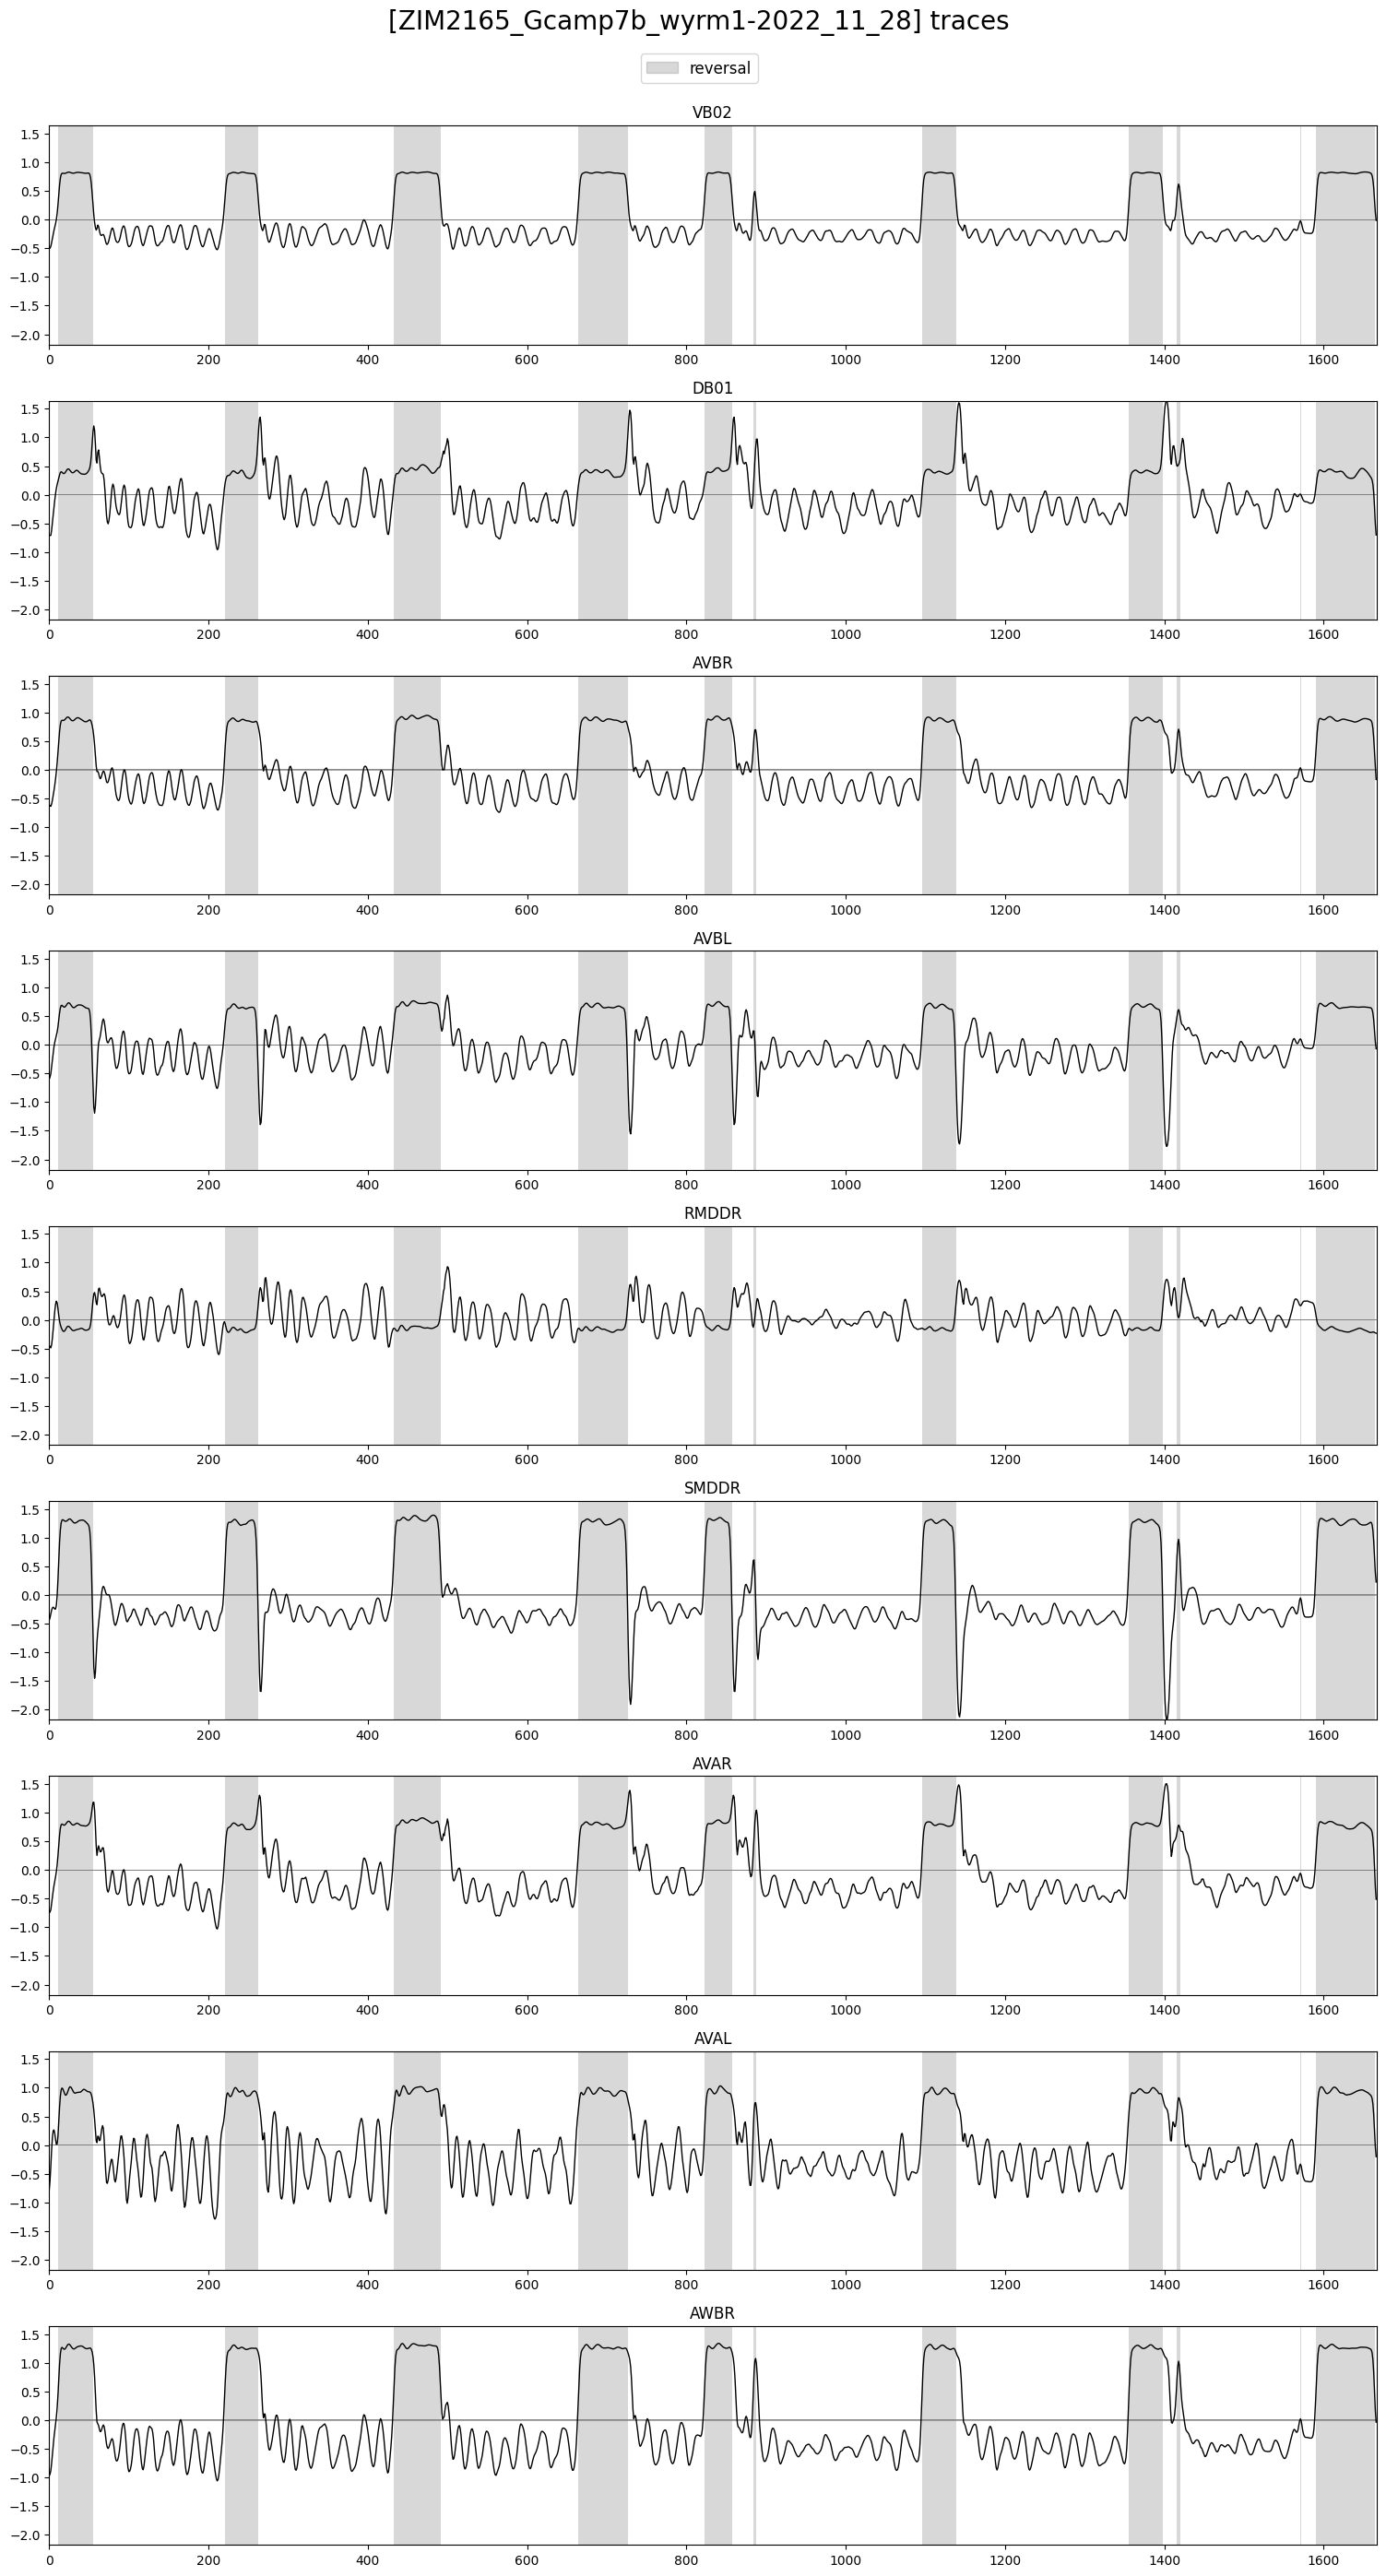

In [34]:
plot_utils.plot_traces(f'[{filename}] traces',
					   discrete_states[['REV']],
					   traces[selection_n],
					   plots_per_row=1, ylimits=None)

# sklearn CCA

In [35]:
X = traces.values
Y = discrete_states.values

In [36]:
cca = CCA(n_components=dims, scale=True)
cca.fit(X, Y)
X_l_h, Y_l_h = cca.transform(X, Y)
X_rec_h, Y_rec_h = cca.inverse_transform(X_l_h, Y_l_h)

# def norm_temp(X_proj):
# 	X_proj = X_proj - np.mean(X_proj, axis=0)
# 	X_proj = X_proj / (np.linalg.norm(X_proj, axis=0) + 1e-6)
# 	return X_proj
# corr_a = np.array(norm_temp(X_l_h).T @ norm_temp(Y_l_h))

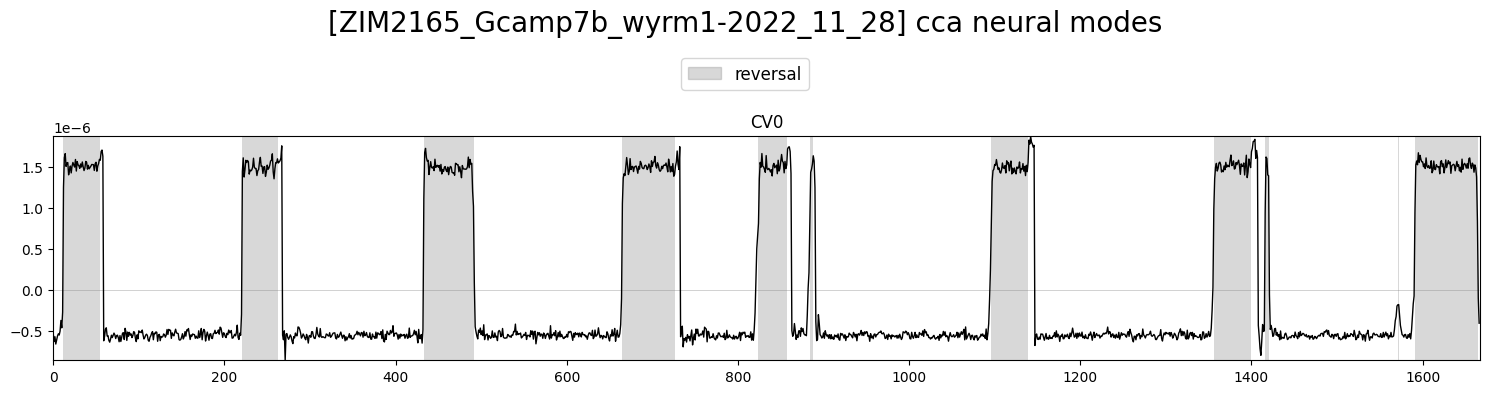

In [37]:
X_l_h_df = pd.DataFrame(data=X_l_h, columns=[f'CV{i}' for i in range(dims)])

plot_utils.plot_traces(f'[{filename}] cca neural modes',
					   discrete_states[['REV']],
					   [X_l_h_df],
					   plots_per_row=1, ylimits=None)

In [38]:
Y_l_h_df = pd.DataFrame(data=Y_l_h, columns=[f'CV{i}' for i in range(dims)])

# plot_utils.plot_traces(f'[{filename}] cca behavioral modes',
# 					   discrete_states[['REV']],
# 					   [Y_l_h_df],
# 					   plots_per_row=1, ylimits=None)

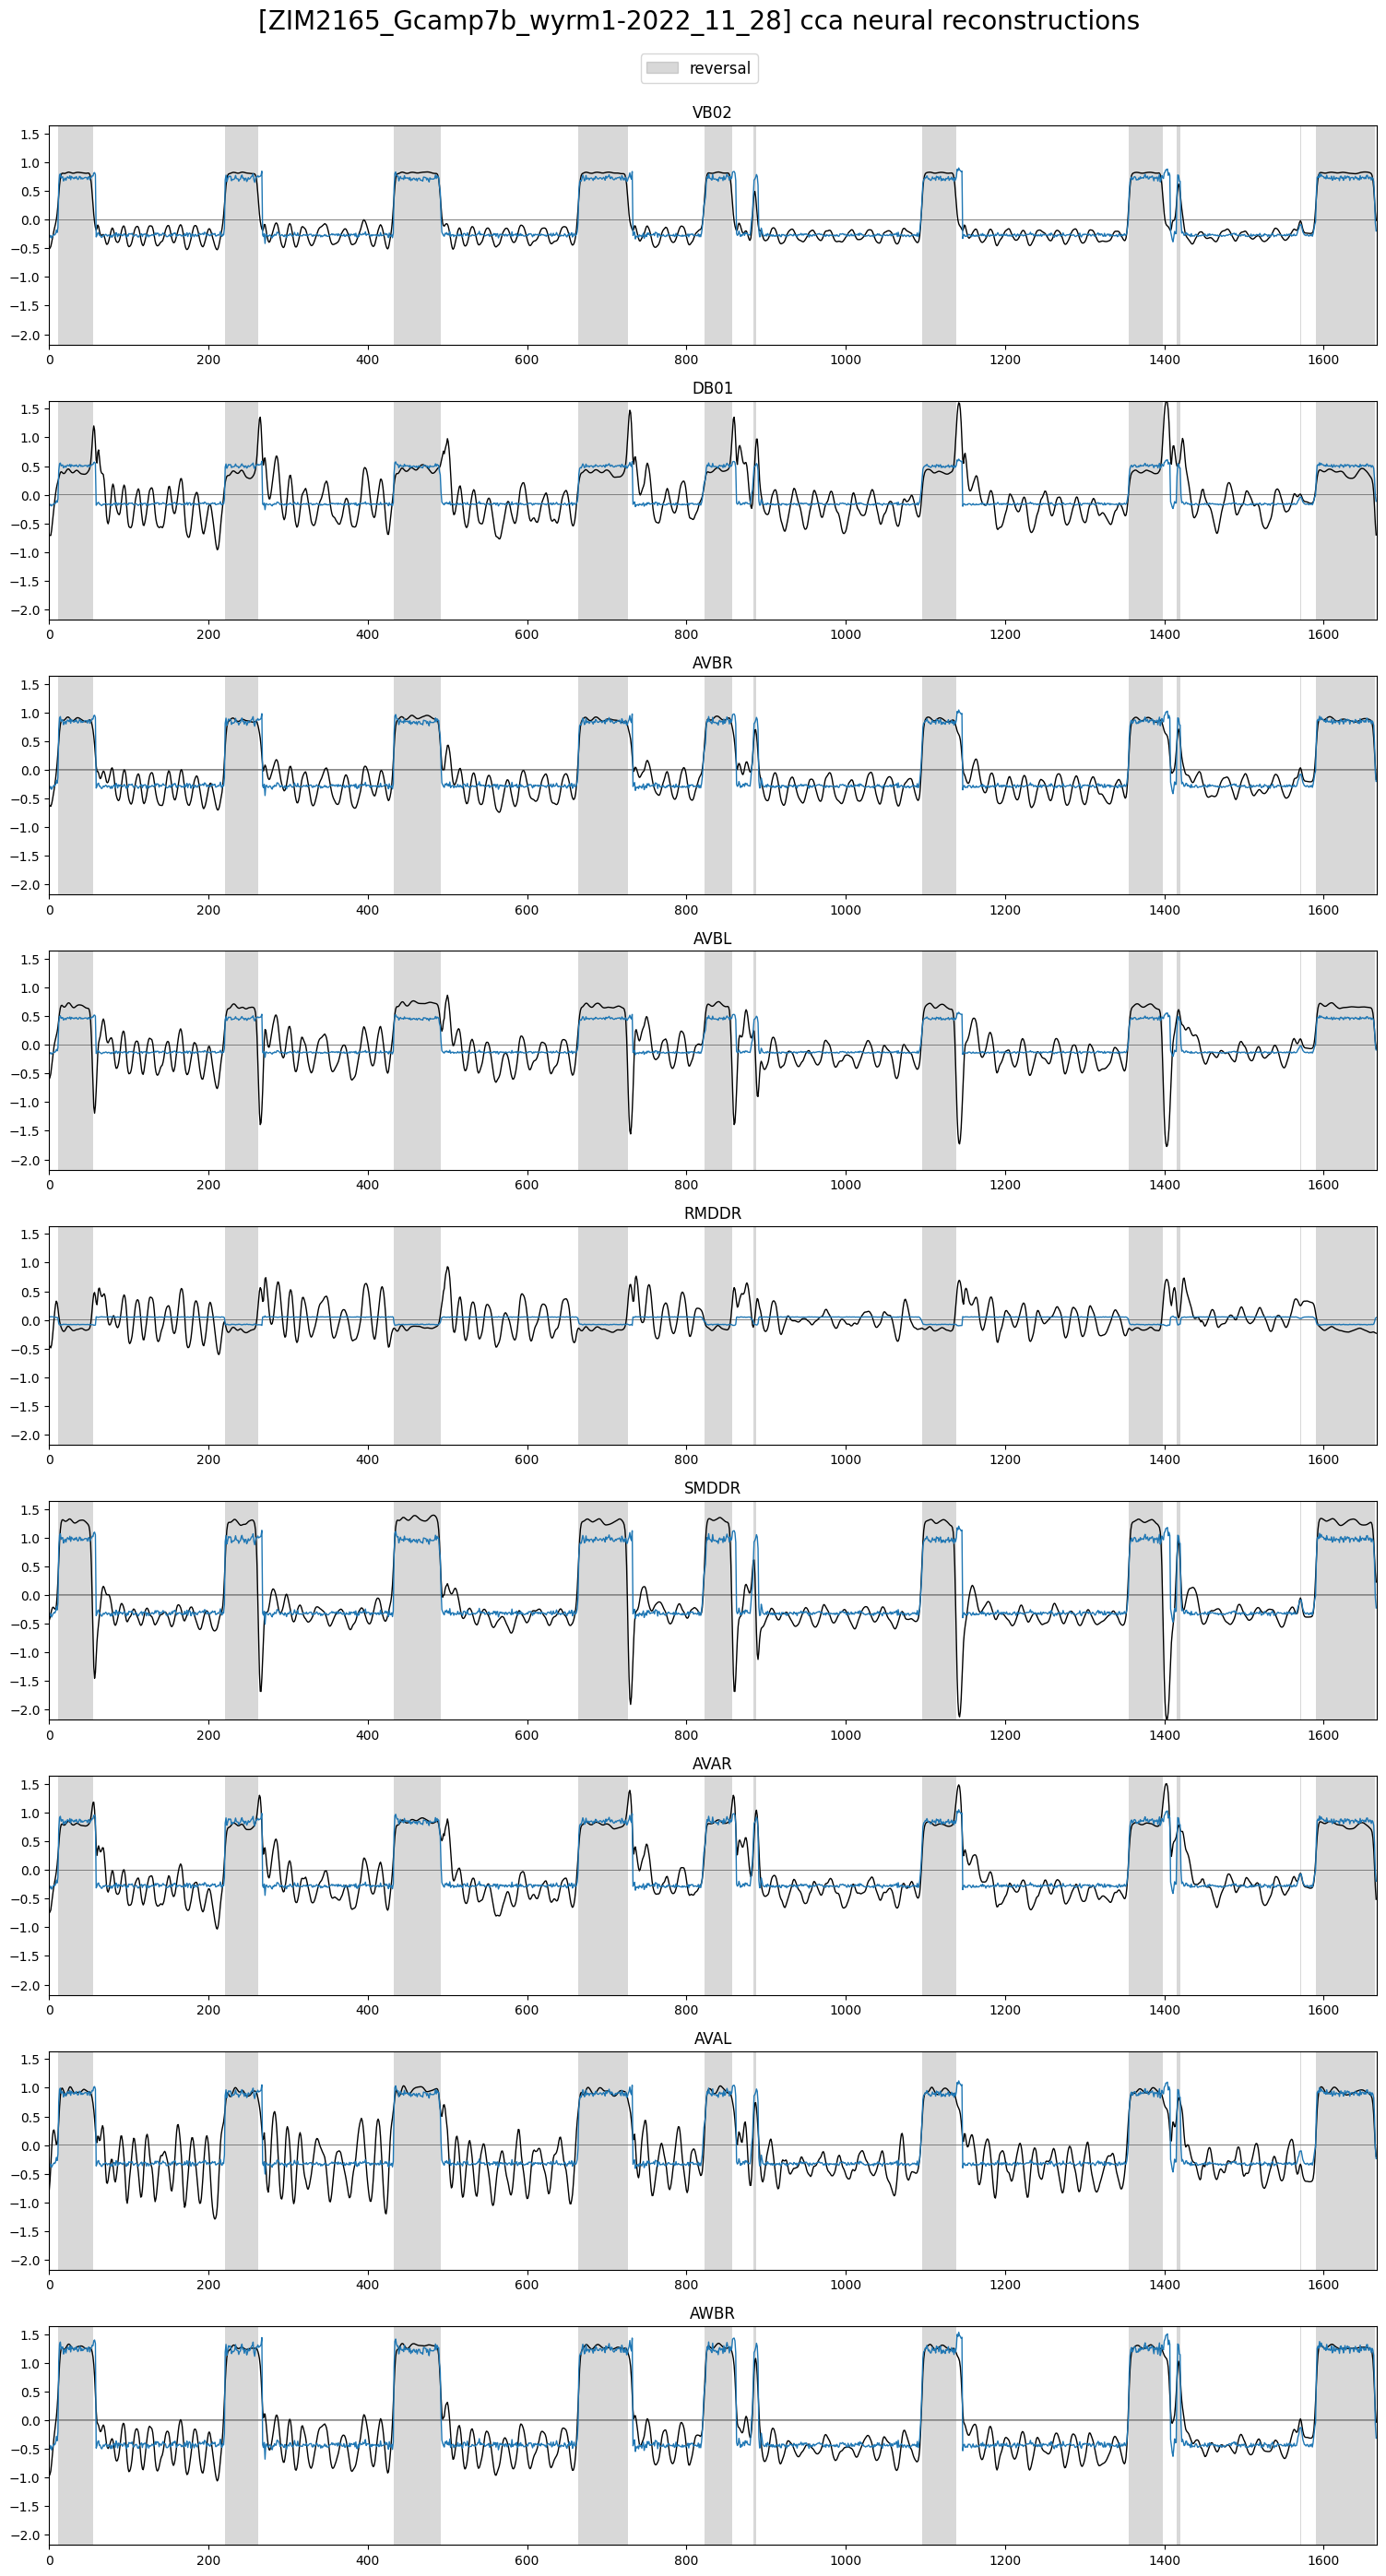

In [39]:
X_rec_h_df = pd.DataFrame(data=X_rec_h, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca neural reconstructions',
					   discrete_states[['REV']],
					   [traces[selection_n], X_rec_h_df[selection_n]],
					   plots_per_row=1, ylimits=None)

In [40]:
Y_rec_h_df = pd.DataFrame(data=Y_rec_h, columns=discrete_states.columns)

# plot_utils.plot_traces(f'[{filename}] cca behavioral reconstructions',
# 					   discrete_states[['REV']],
# 					   [discrete_states, Y_rec_h_df],
# 					   plots_per_row=1, ylimits=None)

# soft CCA

In [41]:
class Lambdas(NamedTuple):
	cca_lambdas: tuple[float, float]


def init_params(N, B_hl, seeds, shape_U, shape_V):
	return {
		'prep': {
			'N': {
				'mean': N.mean(axis=0),
				'std': jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std),
			},
			'B_hl': {
				'mean': B_hl.mean(axis=0),
				'std': jnp.where((B_hl_std := jnp.std(B_hl, axis=0)) == 0.0, 1.0, B_hl_std),
			},
		},
		'model': {
			'U': 1E-2 * jax.random.normal(seeds[0], shape_U),
			'V': 1E-2 * jax.random.normal(seeds[1], shape_V)
		}
	}


#@jax.jit
def norm(X_proj):
	X_proj = X_proj - jnp.mean(X_proj, axis=0)
	X_proj = X_proj / (jnp.linalg.norm(X_proj, axis=0) + 1e-6)
	return X_proj

@jax.jit
def cca_loss(X_proj, Y_proj, ccadiag_lambda, ccaunit_lambda):
	corr = norm(X_proj).T @ norm(Y_proj)

	corr_diag = jnp.diag(jnp.diag(corr))
	corr_nondiag = corr - corr_diag

	return (ccadiag_lambda * jnp.mean(jnp.abs(corr_nondiag))
			+ ccaunit_lambda * jnp.mean(jnp.abs(corr_diag - jnp.eye(*corr_diag.shape))))

#@jax.jit
def loss_fn(params, N, B_hl, lambdas):
	ccadiag_lambda, ccaunit_lambda = lambdas.cca_lambdas

	# manifold ======================================
	prep_n = jax.lax.stop_gradient(params['prep']['N'])
	prep_b_hl = jax.lax.stop_gradient(params['prep']['B_hl'])

	N_mean, N_std = prep_n['mean'], prep_n['std']
	B_hl_mean, B_hl_std = prep_b_hl['mean'], prep_b_hl['std']

	U = params['model']['U']
	V = params['model']['V']

	N_zs = (N - N_mean) / N_std
	B_hl_zs = (B_hl - B_hl_mean) / B_hl_std

	N_man = N_zs @ U
	B_hl_man = B_hl_zs @ V

	man_loss = cca_loss(N_man, B_hl_man, ccadiag_lambda, ccaunit_lambda)
	# ===============================================

	return man_loss

loss_and_grads = jax.jit(jax.value_and_grad(loss_fn, has_aux=False), static_argnums=(3,))


def update(opt_update, opt_state, params, N, B_hl, lambdas):
	loss, grads = loss_and_grads(params, N, B_hl, lambdas)
	params_updates, opt_state = opt_update(grads, opt_state, params)
	params_new = optax.apply_updates(params, params_updates)
	return opt_state, params_new, loss

In [42]:
def soft_cca_train(N, B_hl, hyperparams):
	max_epochs = hyperparams['max_epochs']
	n_dimensions = hyperparams['dimensions']
	learning_rate = hyperparams['learning_rate']
	lambdas = Lambdas(cca_lambdas=(hyperparams['ccadiag_lambda'], hyperparams['ccaunit_lambda']))

	n_neurons = N.shape[1]
	n_behaviors_hl = B_hl.shape[1]

	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1)

	params = init_params(N, B_hl, seeds, (n_neurons, n_dimensions), (n_behaviors_hl, n_dimensions))
	optimizer = optax.adam(learning_rate)
	optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
	opt_state = optimizer.init(params)

	losses_train = []
	for epoch in range(max_epochs):
		opt_state, params, loss_train = update(optimizer.update, opt_state, params, N, B_hl, lambdas)
		losses_train.append(loss_train)

	return params, losses_train


def soft_cca_predict(params, N, B_hl):

	def get_reconstruction_matrix_x(X, X_proj):
		# magic (actually just analytical least-squares solution to reconstruction)
		return np.linalg.inv(X_proj.T @ X_proj) @ X_proj.T @ X
		# return np.linalg.inv(U.T @ U) @ U.T
		# return sp.linalg.pinv(U)

	def get_reconstruction_matrix_y(Y, Y_proj):
		# magic (actually just analytical least-squares solution to reconstruction)
		return np.linalg.inv(Y_proj.T @ Y_proj) @ Y_proj.T @ Y
		# return np.linalg.inv(V.T @ V) @ V.T
		# return sp.linalg.pinv(V)

	prep_n = jax.lax.stop_gradient(params['prep']['N'])
	prep_b_hl = jax.lax.stop_gradient(params['prep']['B_hl'])

	N_mean, N_std = prep_n['mean'], prep_n['std']
	B_hl_mean, B_hl_std = prep_b_hl['mean'], prep_b_hl['std']

	U = params['model']['U']
	V = params['model']['V']

	N_zs = (N - N_mean) / N_std
	B_hl_zs = (B_hl - B_hl_mean) / B_hl_std

	N_man = N_zs @ U
	B_hl_man = B_hl_zs @ V

	N_zs_rec = N_man @ get_reconstruction_matrix_x(N_zs, N_man)
	B_hl_zs_rec = B_hl_man @ get_reconstruction_matrix_y(B_hl_zs, B_hl_man)

	N_rec = N_zs_rec * N_std + N_mean
	B_hl_rec = B_hl_zs_rec * B_hl_std + B_hl_mean

	return np.array(N_man), np.array(B_hl_man), np.array(N_rec), np.array(B_hl_rec)

In [43]:
hyperparameters = {
	'max_epochs': 5000,
	'learning_rate': 1E-1,
	'ccadiag_lambda': 0.6,
	'ccaunit_lambda': 1.0 - 0.6,
	'dimensions': dims
}
params, losses_train = soft_cca_train(X, Y, hyperparameters)
X_l_s, Y_l_s, X_rec_s, Y_rec_s = soft_cca_predict(params, X, Y)

# corr_n = np.array(norming(X_l_s).T @ norming(Y_l_s) / norming(X_l_s).shape[0])

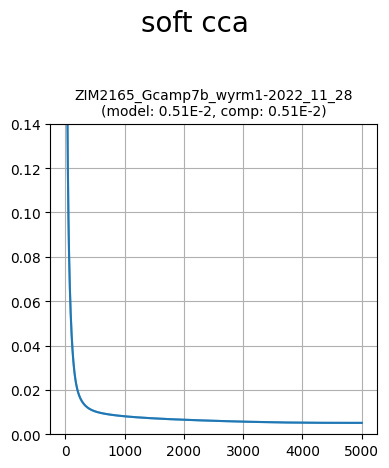

In [44]:
losses = np.array(losses_train)
plot_utils.plot_losses_splits('soft cca', [filename], [np.array([losses])], [np.array([losses])],
							  plots_per_row=1, ylimits=(losses.min(), losses.min() + (losses.max() - losses.min()) * 0.2))

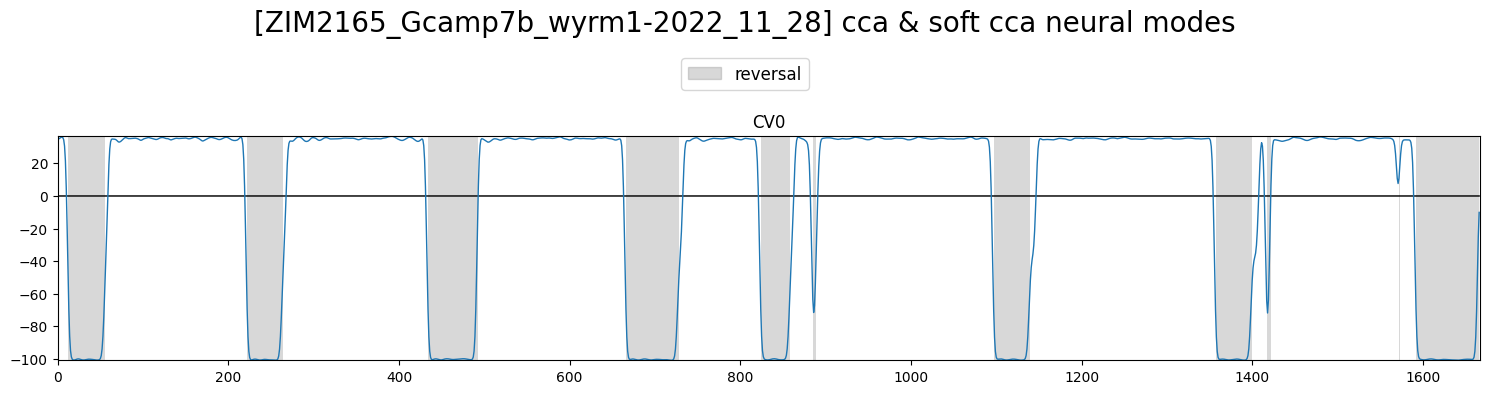

In [45]:
X_l_s_df = pd.DataFrame(data=X_l_s, columns=[f'CV{i}' for i in range(dims)])

plot_utils.plot_traces(f'[{filename}] cca & soft cca neural modes',
					   discrete_states[['REV']],
					   [X_l_h_df, X_l_s_df],
					   plots_per_row=1, ylimits=None)

In [46]:
Y_l_s_df = pd.DataFrame(data=Y_l_s, columns=[f'CV{i}' for i in range(dims)])

# plot_utils.plot_traces(f'[{filename}] cca & soft cca behavioral modes',
# 					   discrete_states[['REV']],
# 					   [Y_l_h_df, Y_l_s_df],
# 					   plots_per_row=1, ylimits=None)

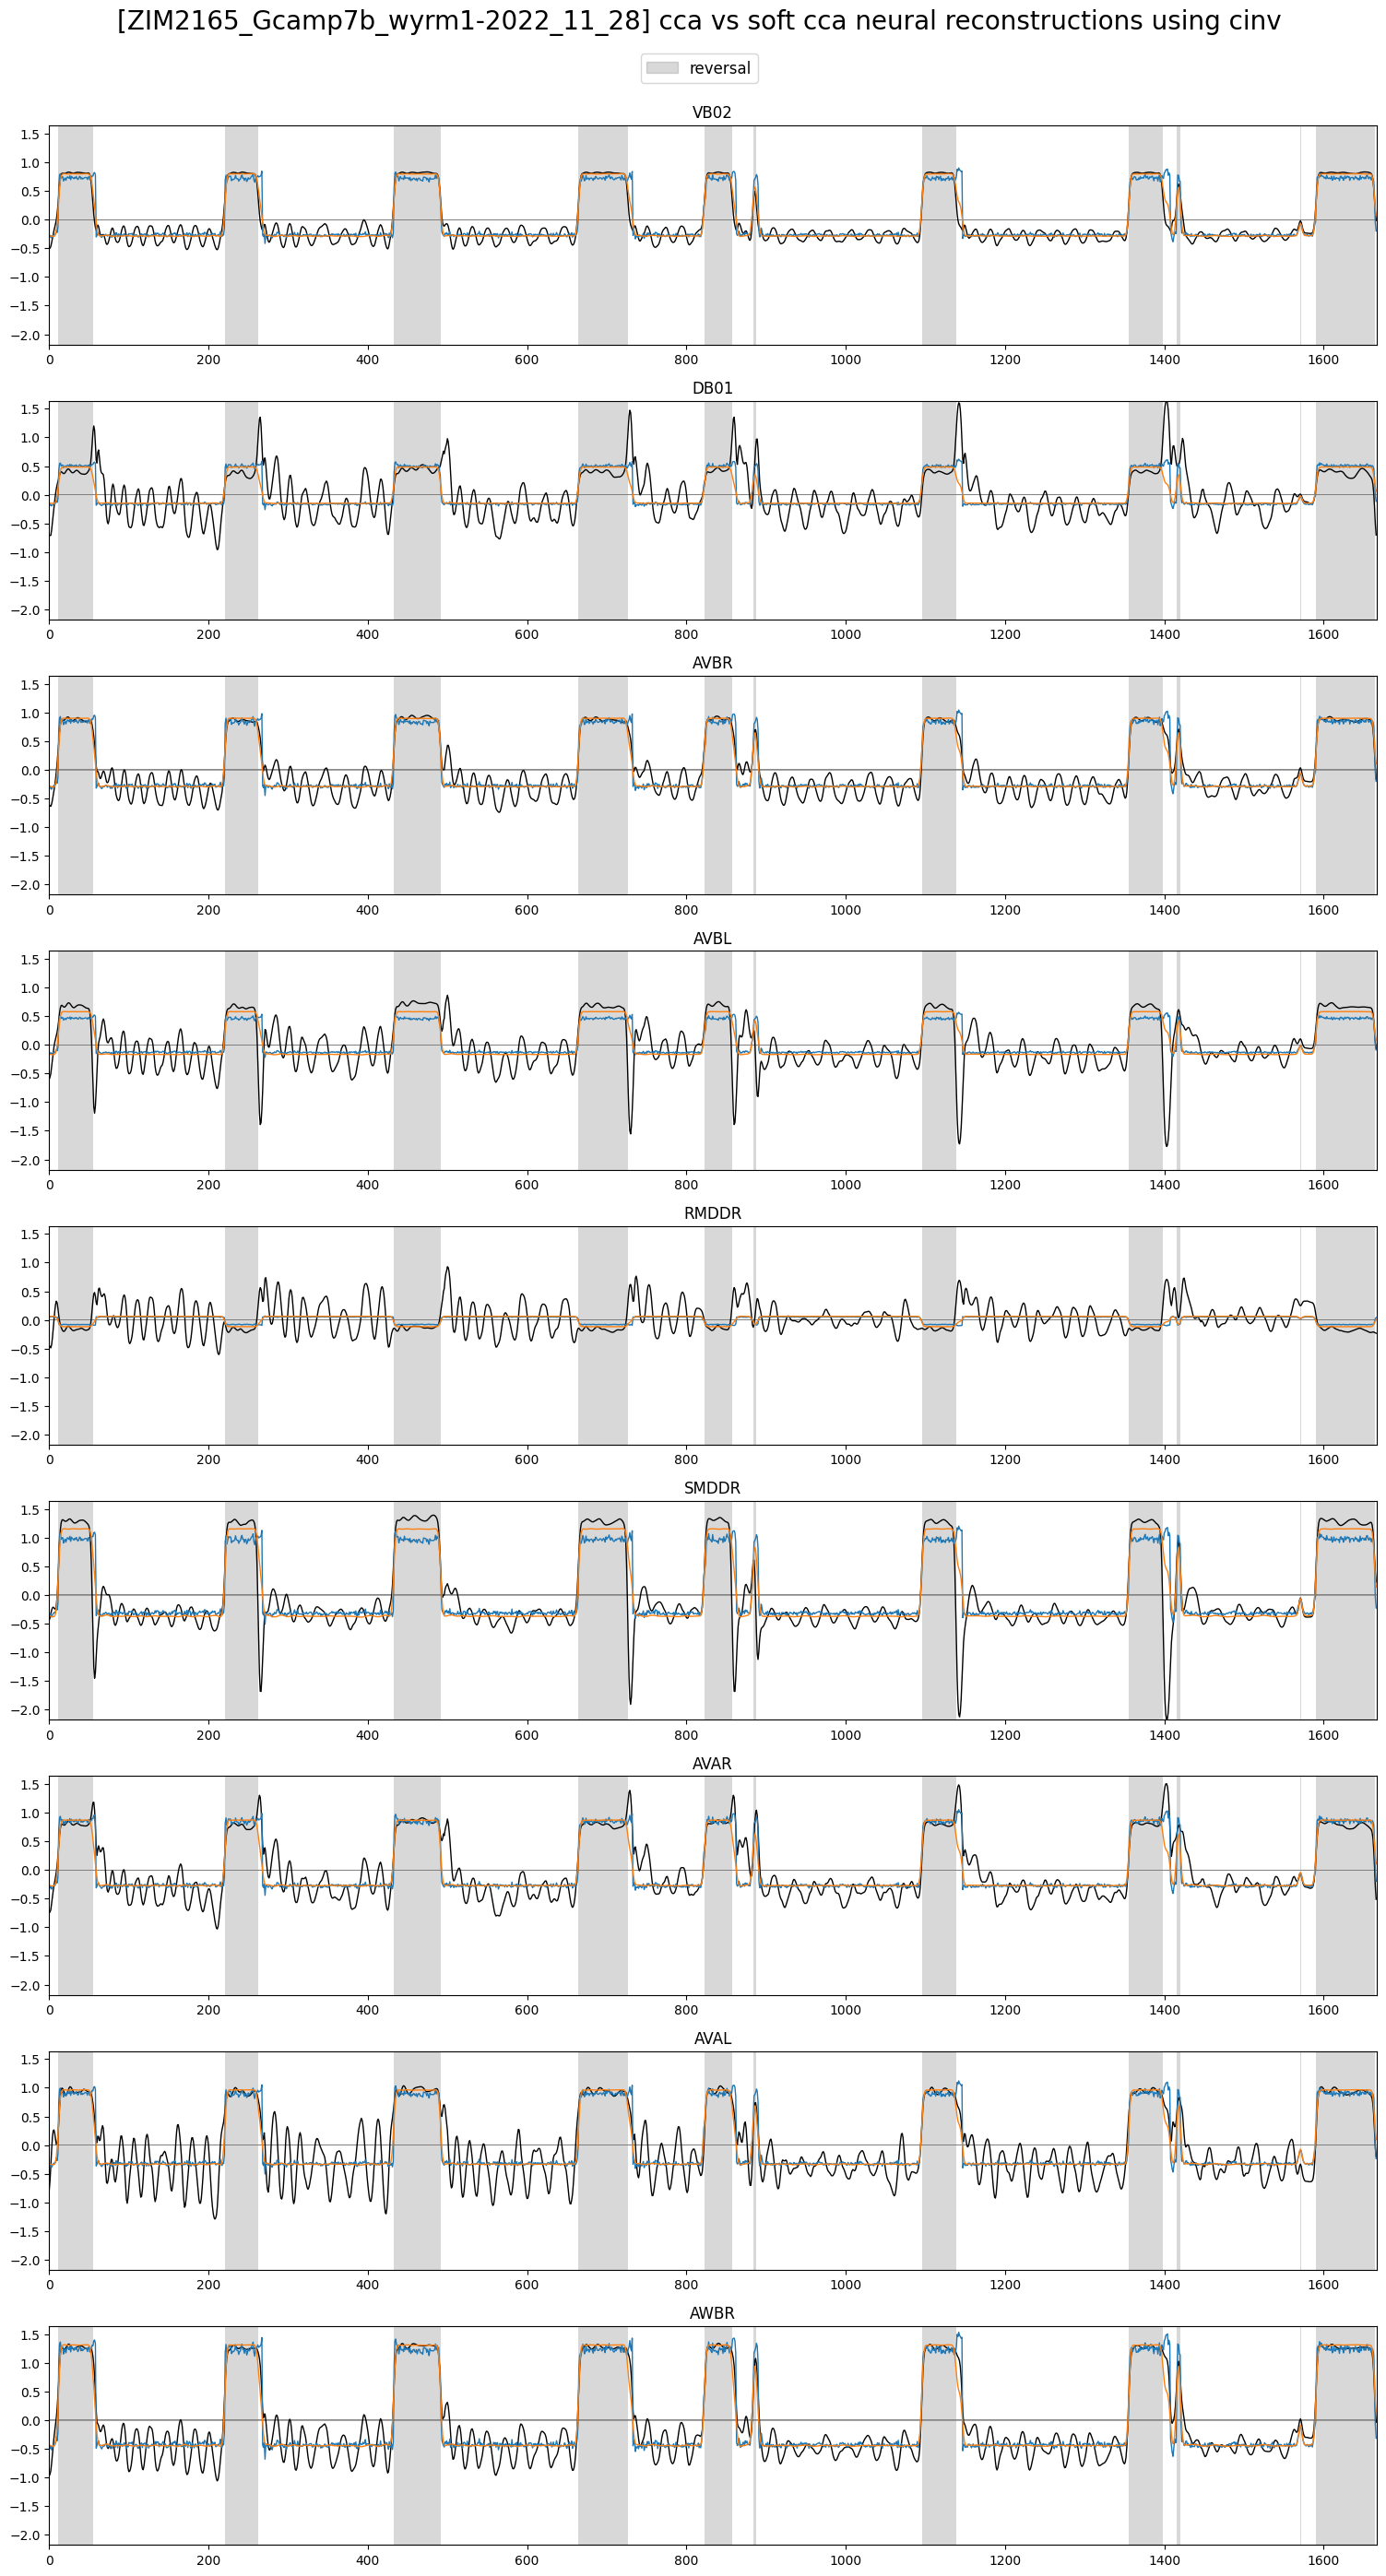

In [47]:
X_rec_s_df = pd.DataFrame(data=X_rec_s, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca vs soft cca neural reconstructions using cinv',
					   discrete_states[['REV']],
					   [traces[selection_n], X_rec_h_df[selection_n], X_rec_s_df[selection_n]],
					   plots_per_row=1, ylimits=None)

In [48]:
Y_rec_s_cinv_df = pd.DataFrame(data=Y_rec_s, columns=discrete_states.columns)

# plot_utils.plot_traces(f'[{filename}] cca vs soft cca behavioral reconstructions using cinv',
# 					   discrete_states[['REV']],
# 					   [discrete_states, Y_rec_h_df, Y_rec_s_cinv_df],
# 					   plots_per_row=1, ylimits=None)

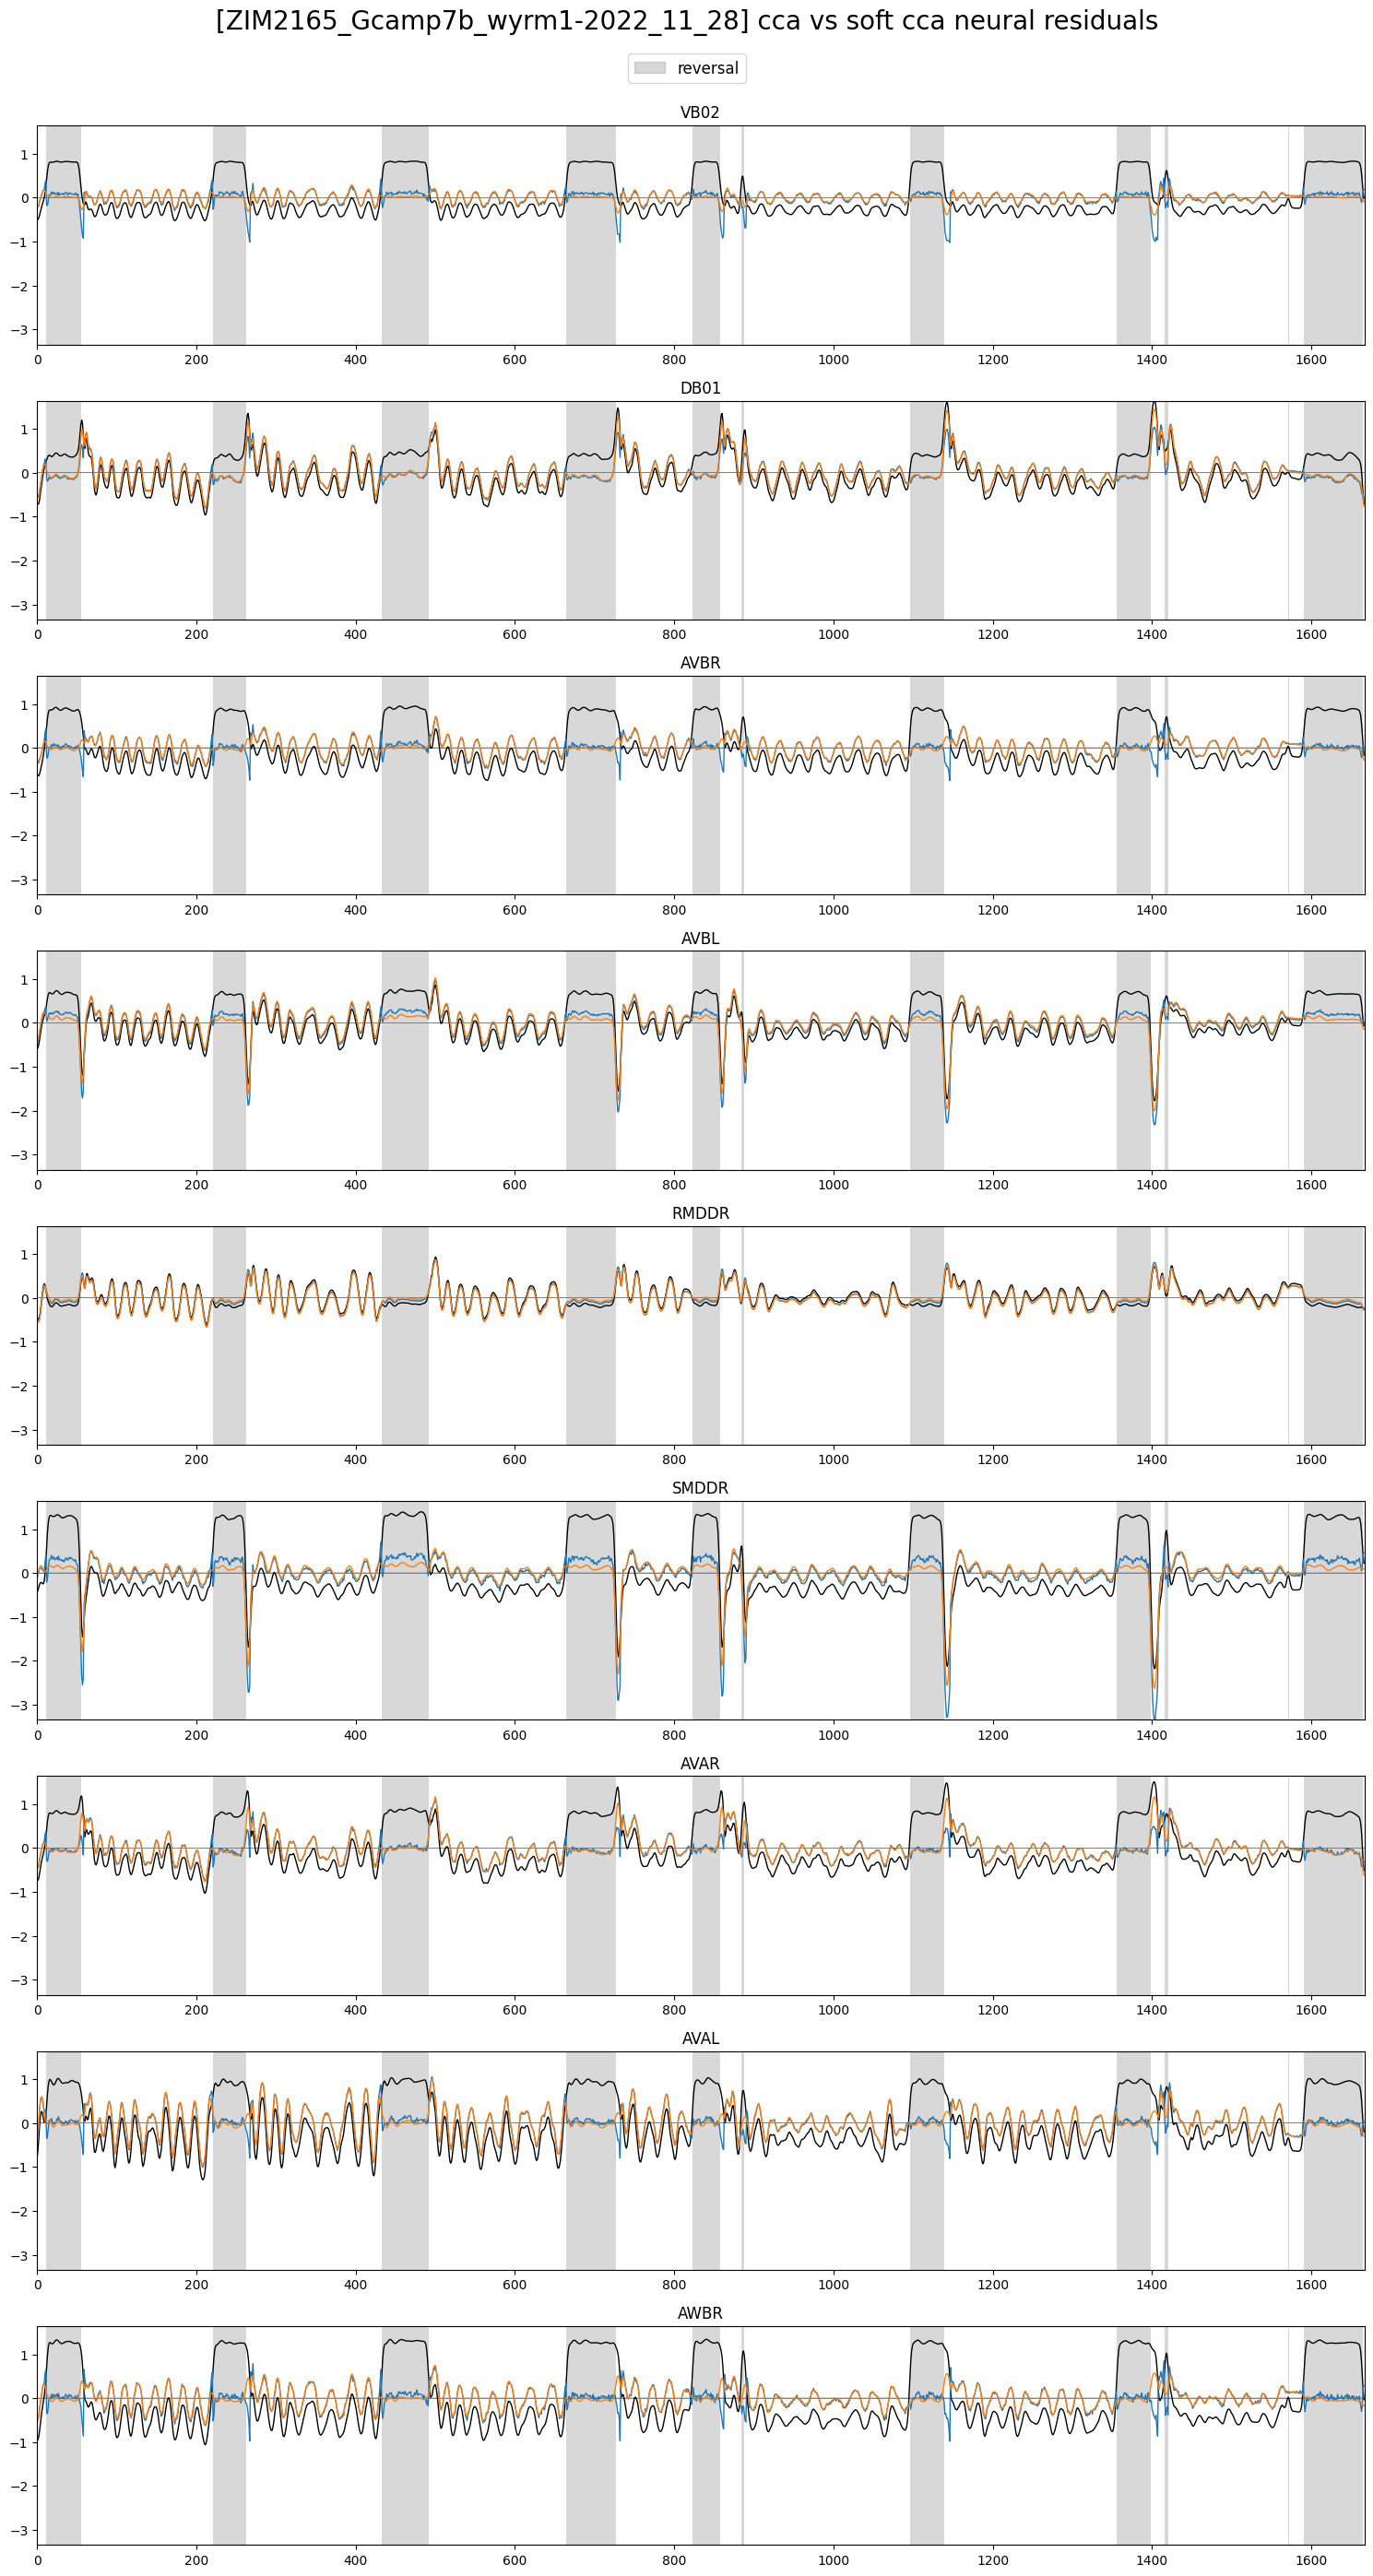

In [49]:
X_res_h_df = pd.DataFrame(data=X - X_rec_h, columns=traces.columns)
X_res_s_df = pd.DataFrame(data=X - X_rec_s, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca vs soft cca neural residuals',
					   discrete_states[['REV']],
					   [traces[selection_n], X_res_h_df[selection_n], X_res_s_df[selection_n]],
					   plots_per_row=1)

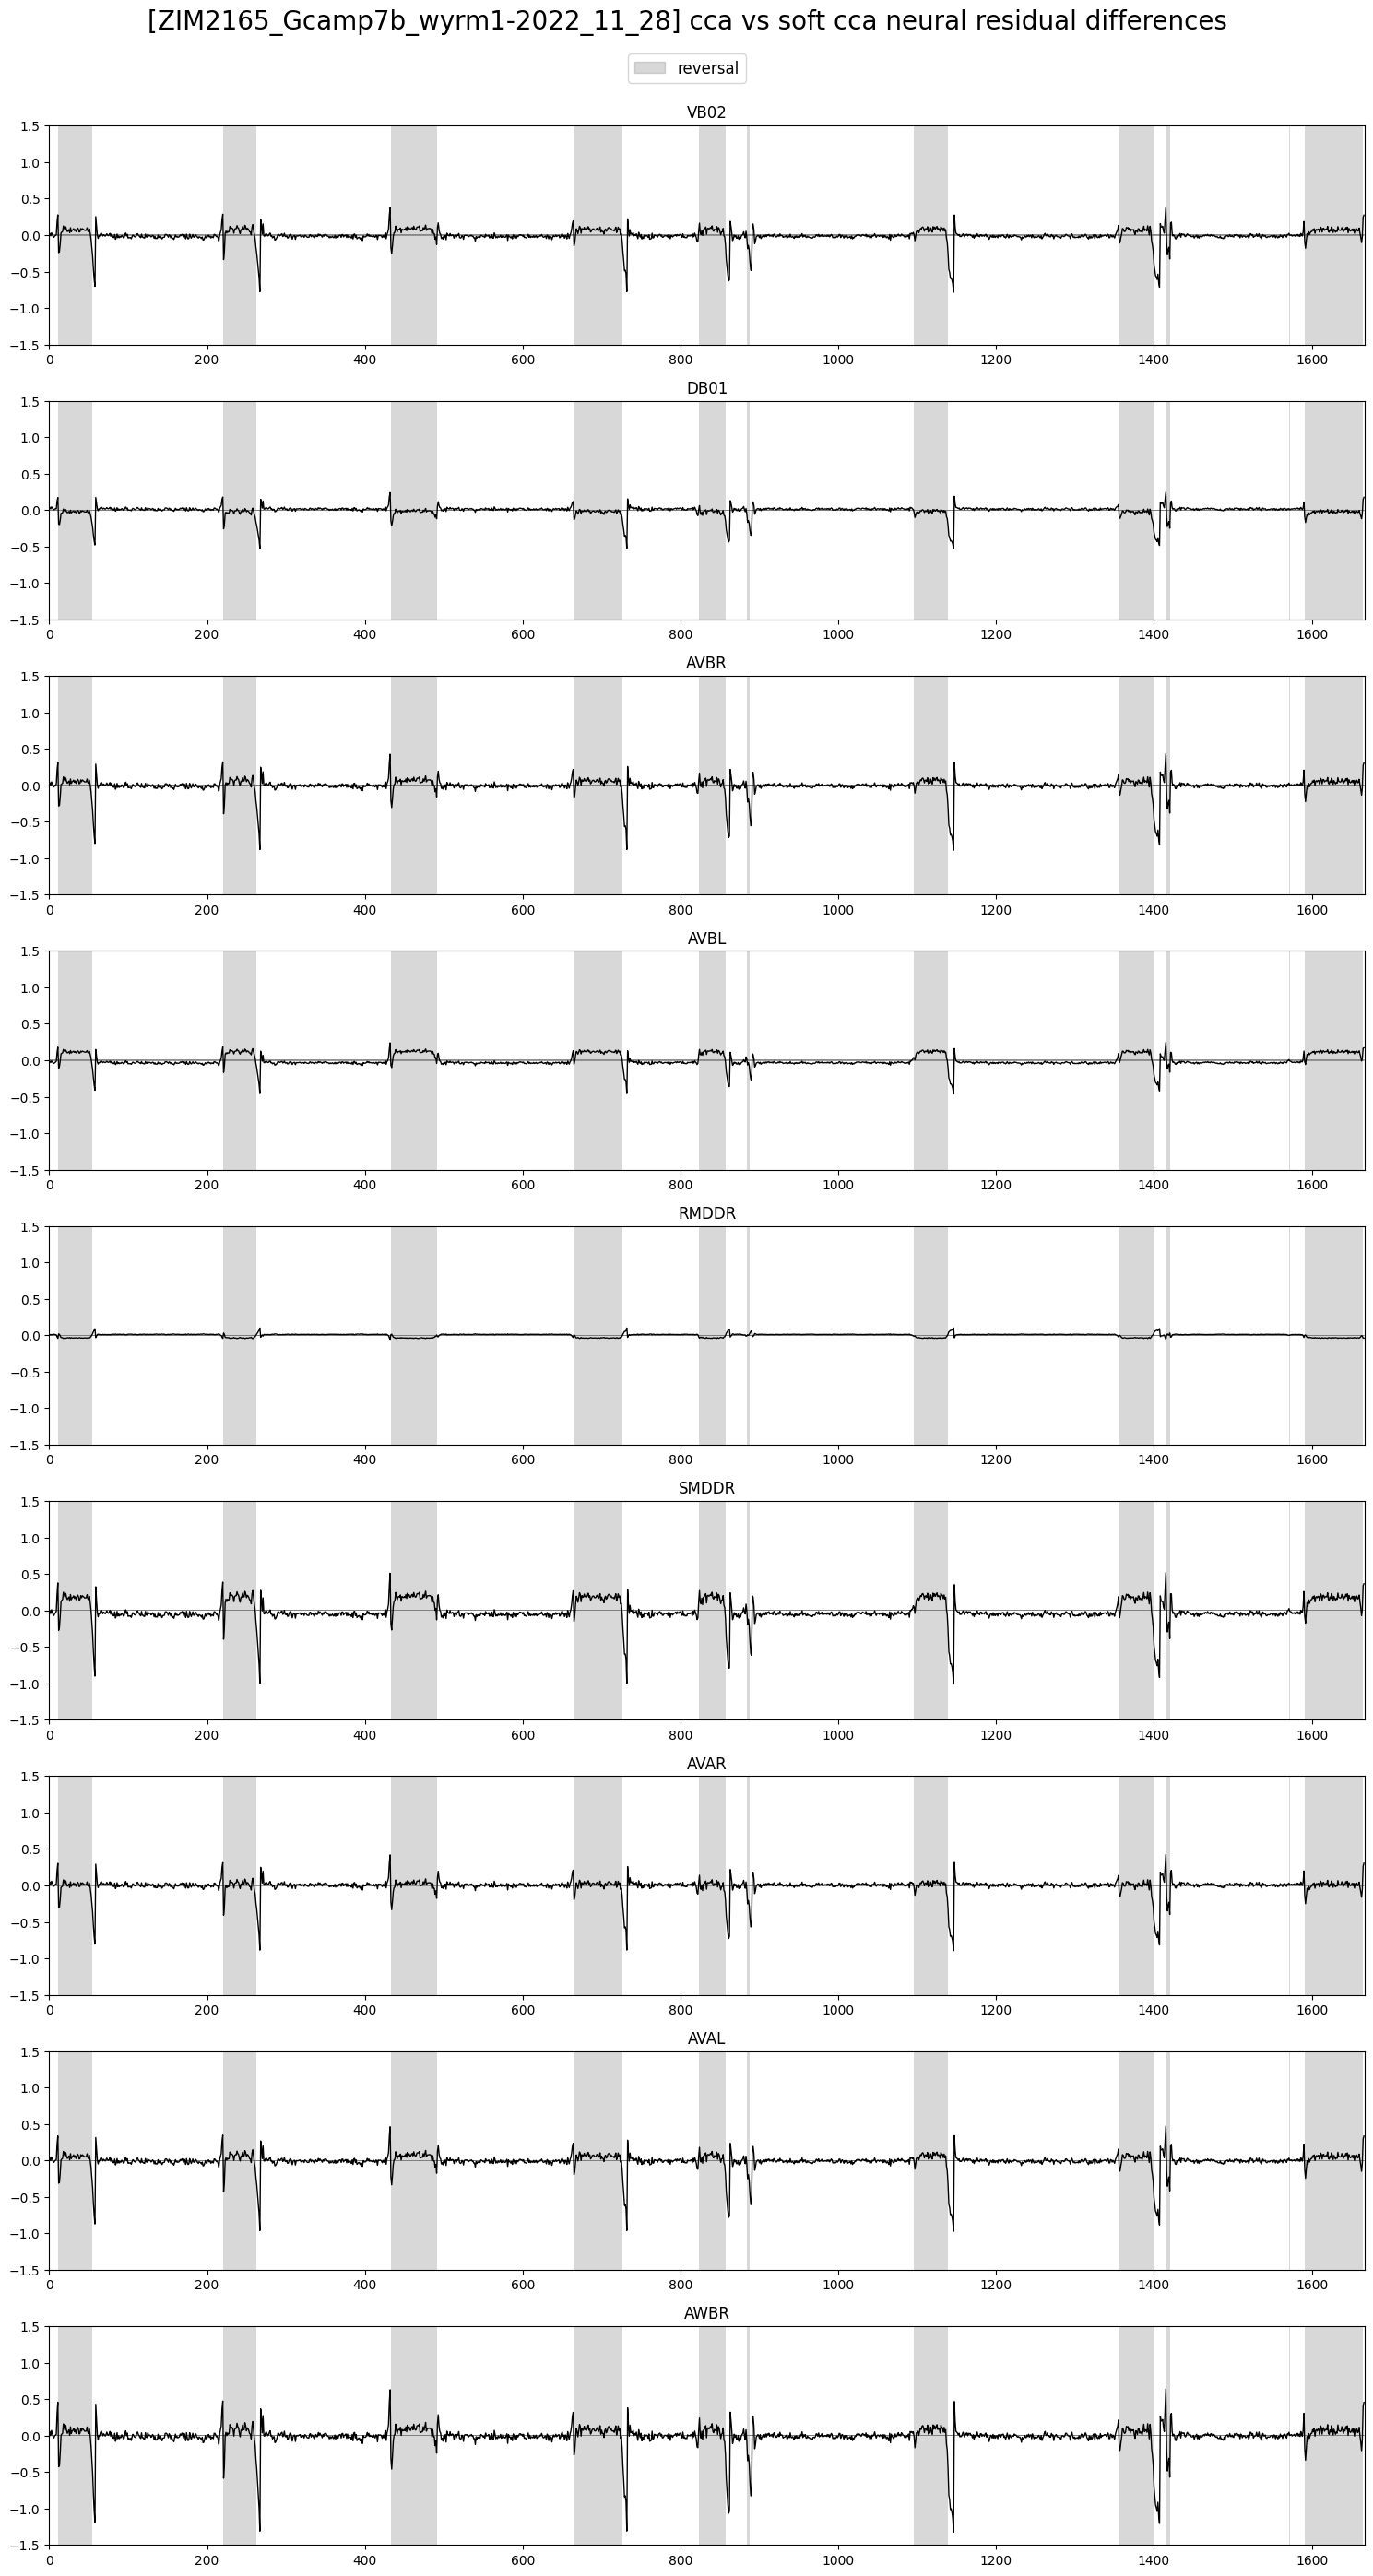

In [50]:
plot_utils.plot_traces(f'[{filename}] cca vs soft cca neural residual differences',
					   discrete_states[['REV']],
					   [X_res_h_df[selection_n] - X_res_s_df[selection_n]],
					   plots_per_row=1, ylimits=(-1.5, 1.5))